In [1]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import nbimporter
from preprocessing_feature_selection import get_breast_cancer

# to get standardized X features function parameter => std='std'
X_train, X_test, y_train, y_test = get_breast_cancer()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.naive_bayes import GaussianNB

In [6]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB()
}

In [7]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
print("All Model Trained Successfully")

All Model Trained Successfully


In [8]:
display(
    results_df.sort_values(
        by="ROC AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.964912,0.975000,0.928571,0.951220,0.996032
5,Gradient Boosting,0.964912,1.000000,0.904762,0.950000,0.994709
2,SVM,0.973684,1.000000,0.928571,0.962963,0.994709
4,Random Forest,0.973684,1.000000,0.928571,0.962963,0.994378
6,Naive Bayes,0.938596,1.000000,0.833333,0.909091,0.993386
1,KNN,0.956140,0.974359,0.904762,0.938272,0.982308
3,Decision Tree,0.929825,0.904762,0.904762,0.904762,0.924603


## Model Evaluation Metrics

| Metric | What It Tells You |
|---|---|
| Accuracy | Overall proportion of correct predictions. |
| Precision | How many predicted malignant cases are actually malignant. |
| Recall | How many actual malignant cases were correctly identified. |
| F1-Score | Harmonic mean of precision and recall, balancing both metrics. |
| ROC-AUC | How well the model distinguishes between benign and malignant classes. |

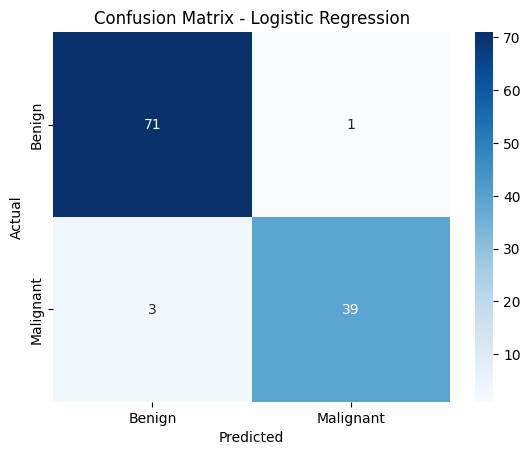

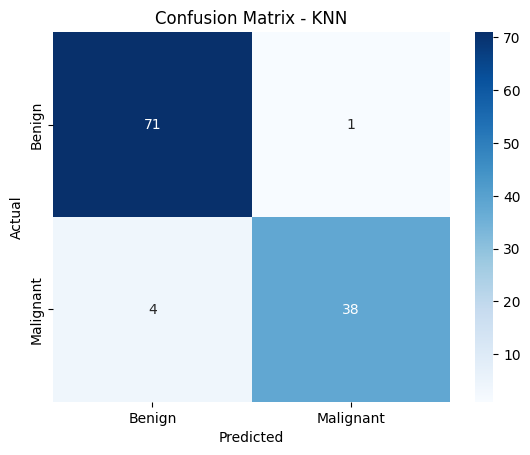

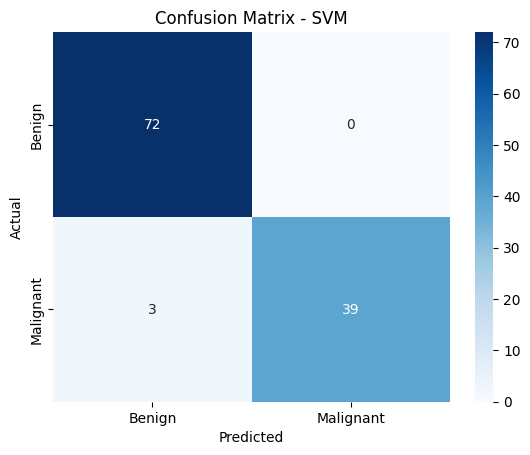

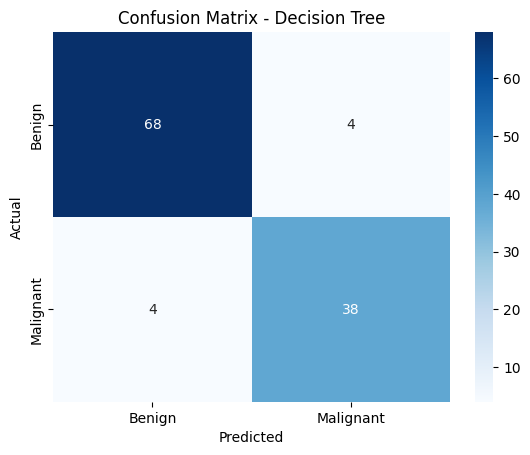

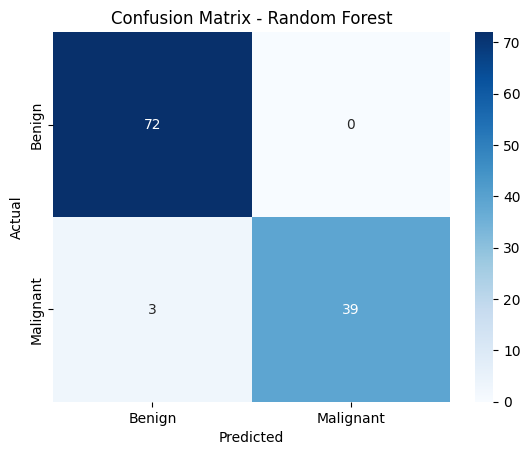

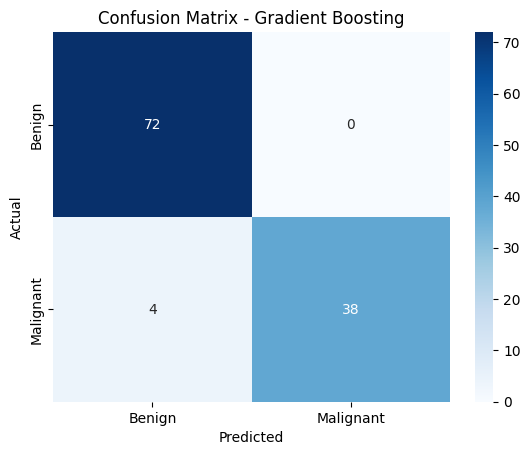

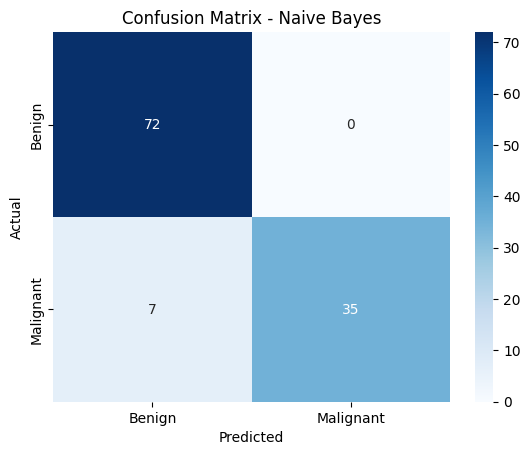

In [11]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

for model in models.keys():
    current_model = models[model]

    y_pred = current_model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {model}")
    plt.show()

In [17]:
from sklearn.metrics import classification_report

for model in models.keys():
    current_model = models[model]

    y_pred = current_model.predict(X_test)

    print(f"\nClassification Report: {model}")
    print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"]
    )
)


Classification Report: Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


Classification Report: KNN
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Classification Report: SVM
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98     

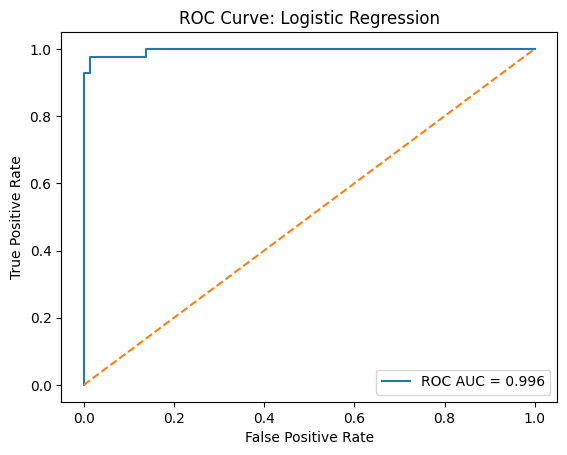

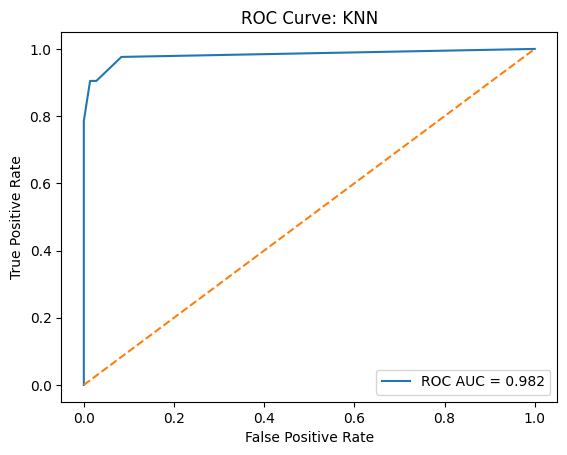

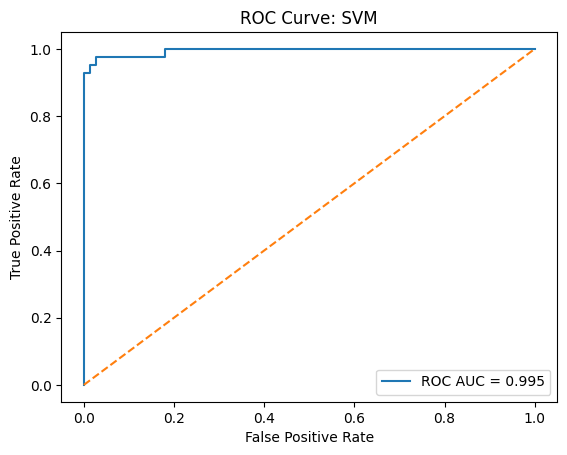

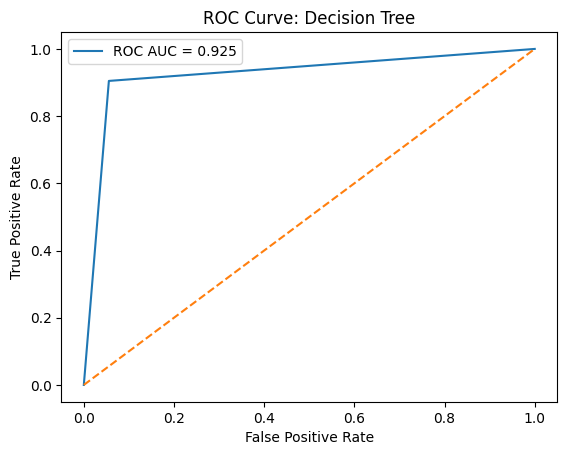

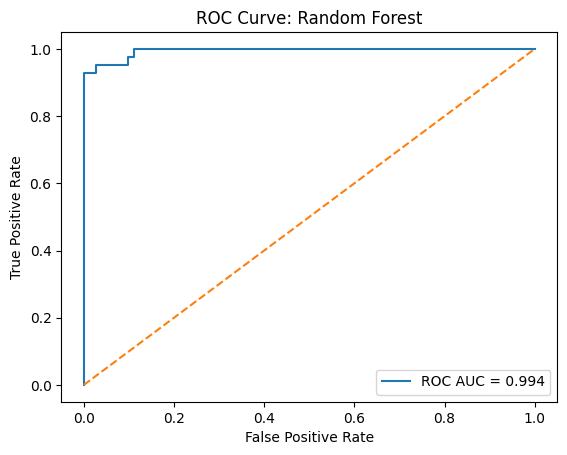

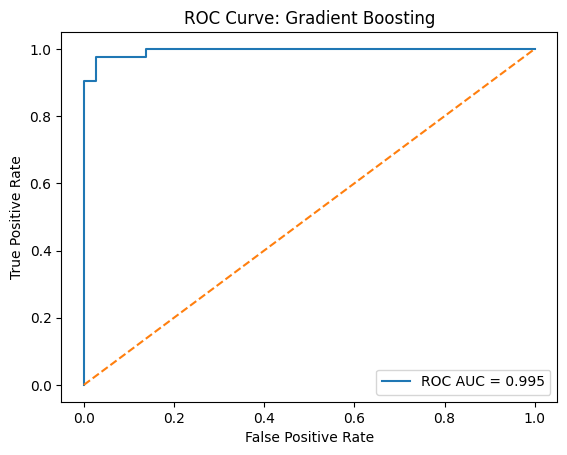

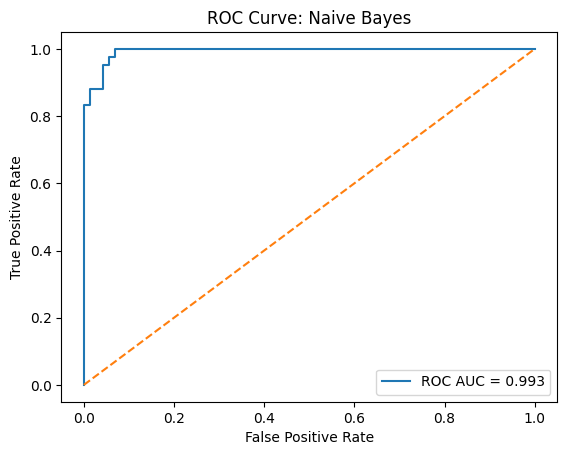

In [18]:
from sklearn.metrics import roc_curve, auc

for model in models.keys():
    current_model = models[model]

    y_prob = current_model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"ROC AUC = {roc_auc:.3f}"
    )

    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve: {model}")
    plt.legend()
    plt.show()

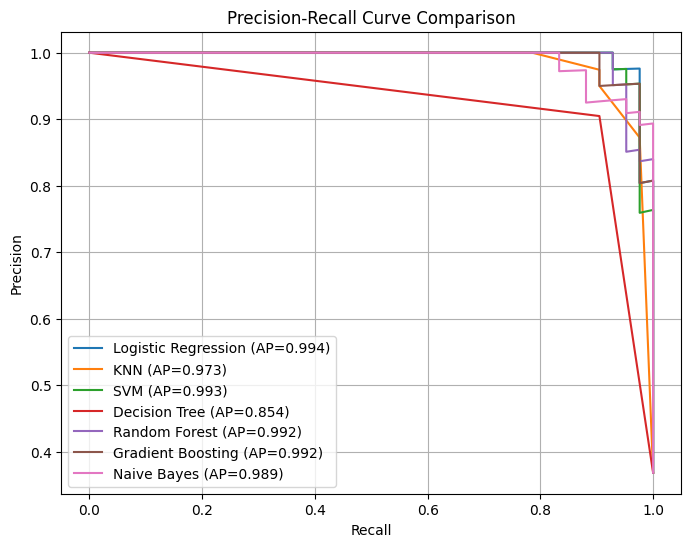

In [ ]:
# Precision-Recall curve
# A Precision-Recall curve shows the trade-off between precision and recall at different classification thresholds.
# This is particularly useful for medical classification because identifying malignant cases is important.

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test, y_prob
    )

    ap = average_precision_score(y_test, y_prob)

    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()
plt.show()

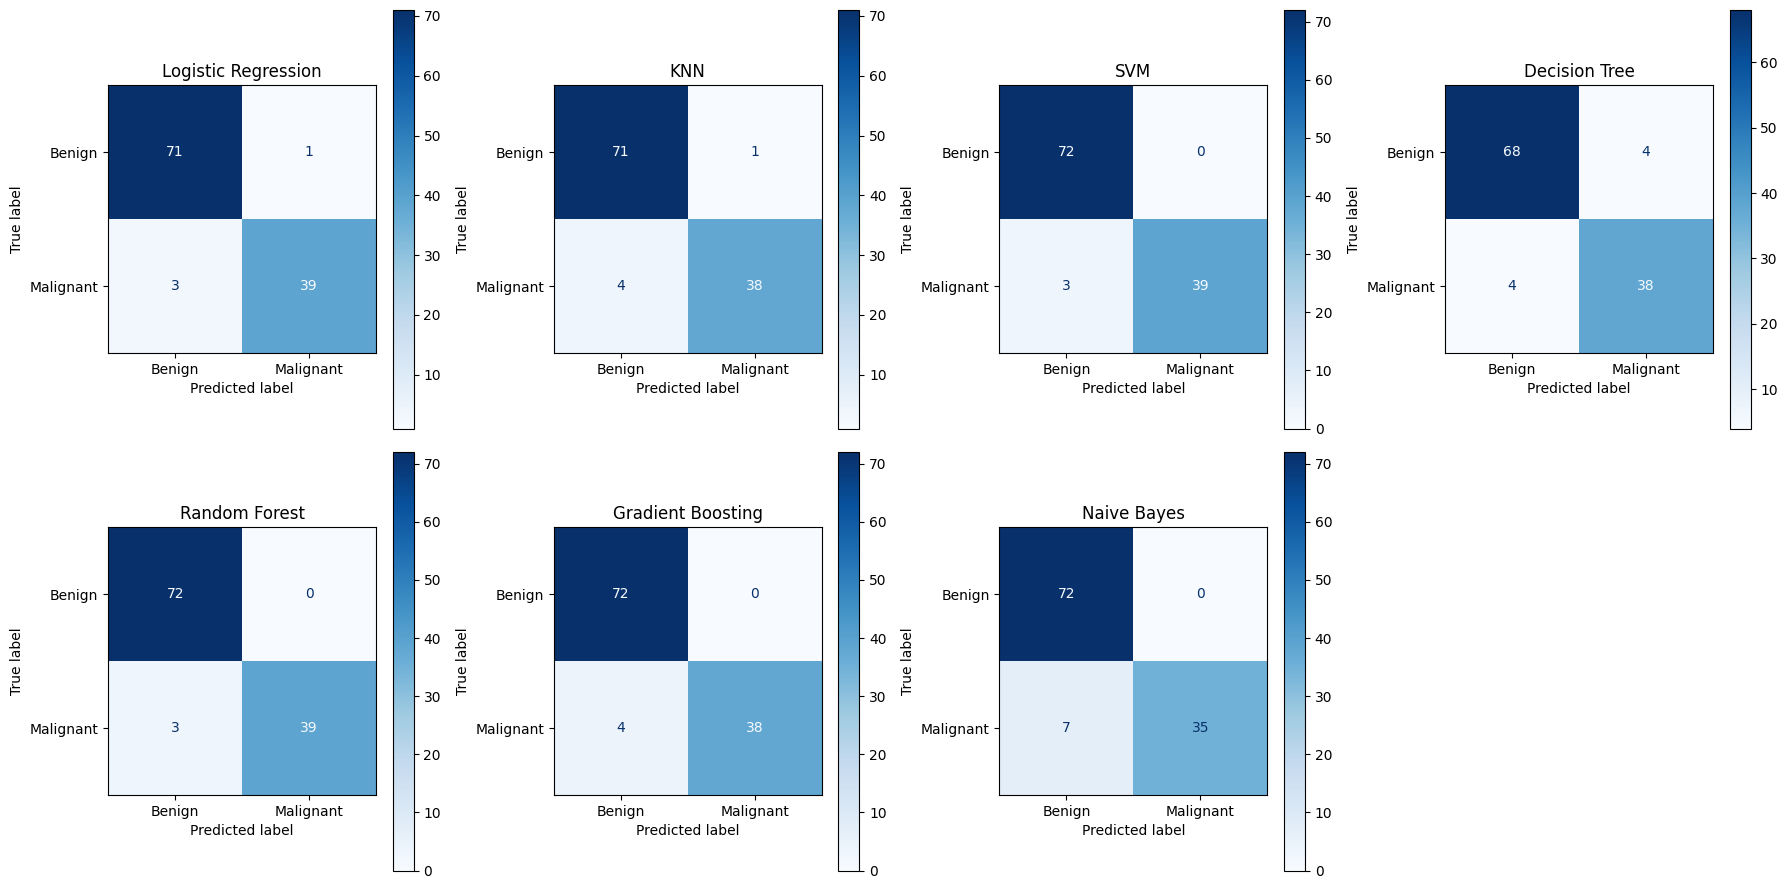

In [ ]:
# Individual confusion matrices
# Instead of visualizing only the best model, generate confusion matrices for all seven models.
# This helps identify which algorithms produce more false negatives and false positives.

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(name)

for j in range(len(models), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cross-validation score comparison
# A single train-test split may produce misleading results.

# Use stratified cross-validation to evaluate model stability across multiple data splits.

from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

In [26]:
display(cv_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
))

,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.995769,0.004666
2,SVM,0.994943,0.004964
5,Gradient Boosting,0.990815,0.005523
4,Random Forest,0.987977,0.007282
6,Naive Bayes,0.987822,0.007475
1,KNN,0.987100,0.013582
3,Decision Tree,0.917234,0.037542


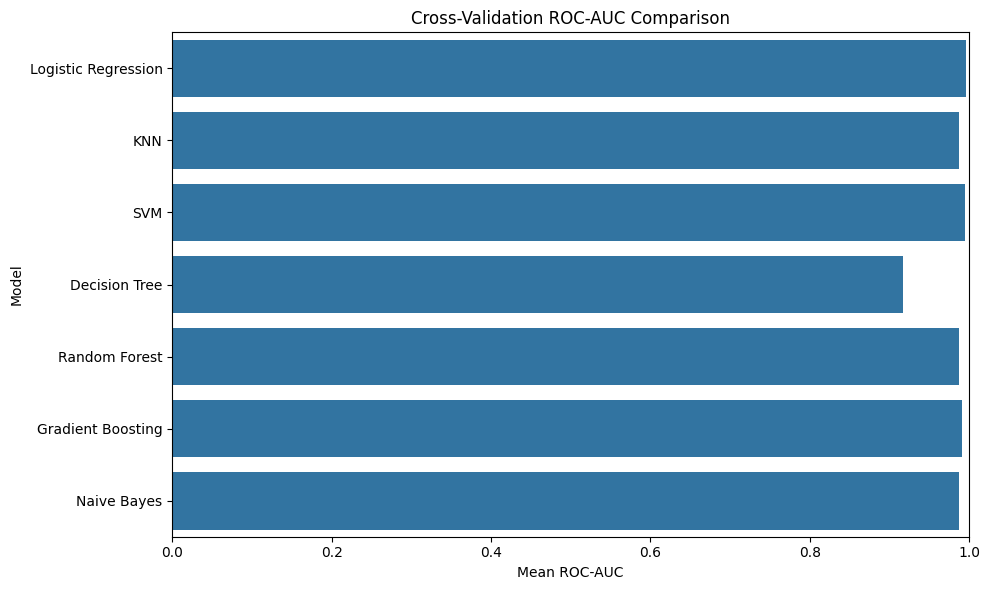

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_df,
    x="Mean ROC-AUC",
    y="Model"
)

plt.xlim(0, 1)
plt.title("Cross-Validation ROC-AUC Comparison")
plt.tight_layout()
plt.show()

# Selecting Random Forest as the Best Model for Further Analysis
The following steps and techniques can also be applied to other machine learning models.

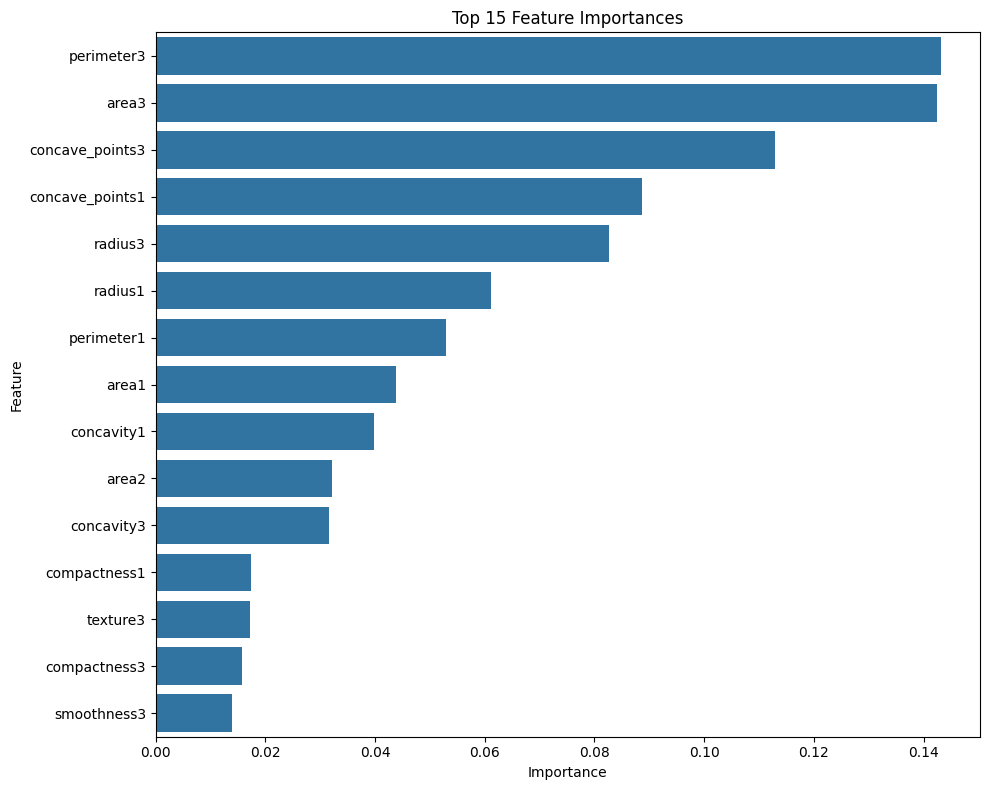

In [ ]:
# Feature importance analysis
# Identify which input features contribute most to model predictions.
# This is particularly useful for understanding which measurements have a strong influence on classification.

rf_model = models["Random Forest"]

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

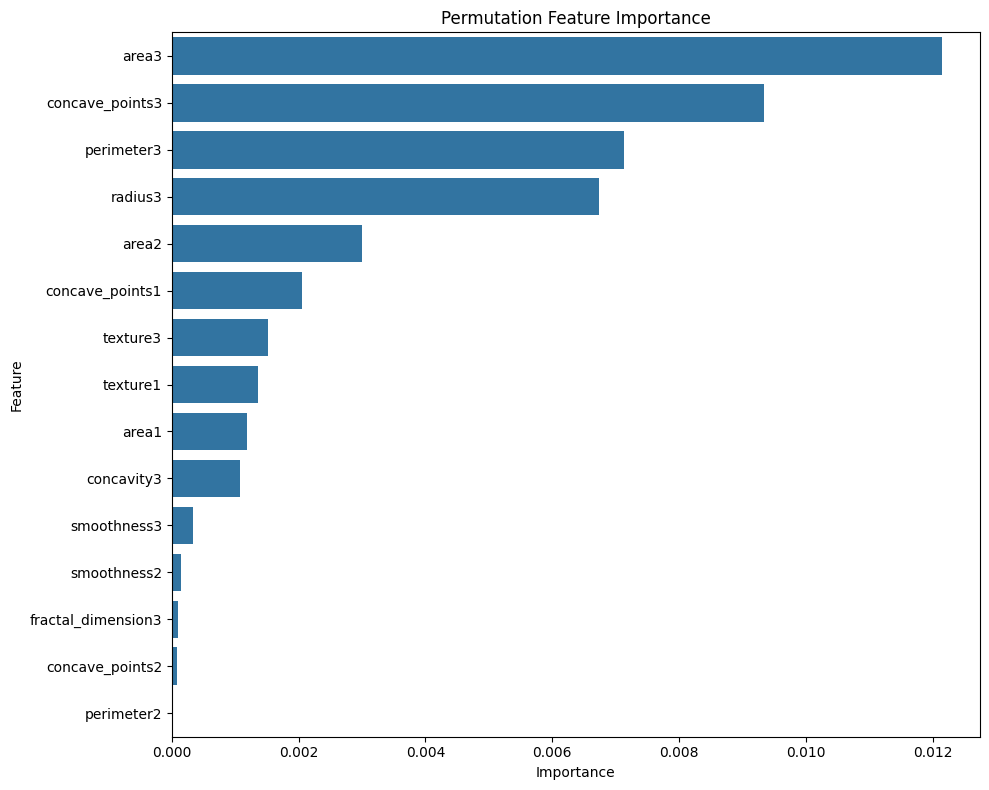

In [ ]:
# Permutation feature importance

# Permutation importance measures how much model performance decreases when a feature's values are shuffled.

from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

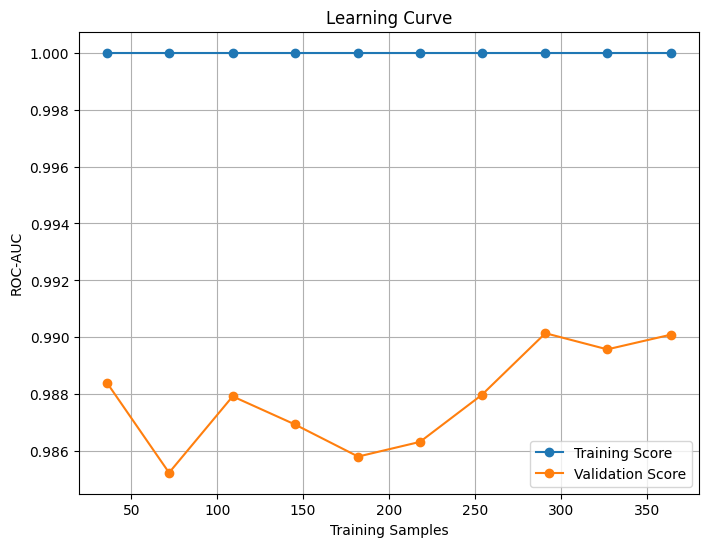

In [ ]:
# Learning curve
# A learning curve shows how model performance changes as the amount of training data increases.

# It helps identify:
# - Overfitting
# - Underfitting
# - Whether additional training data might improve performance

from sklearn.model_selection import learning_curve
import numpy as np

train_sizes, train_scores, validation_scores = learning_curve(
    models["Random Forest"],
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

plt.figure(figsize=(8, 6))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training Score"
)

plt.plot(
    train_sizes,
    validation_scores.mean(axis=1),
    marker="o",
    label="Validation Score"
)

plt.xlabel("Training Samples")
plt.ylabel("ROC-AUC")
plt.title("Learning Curve")
plt.legend()
plt.grid()

plt.show()

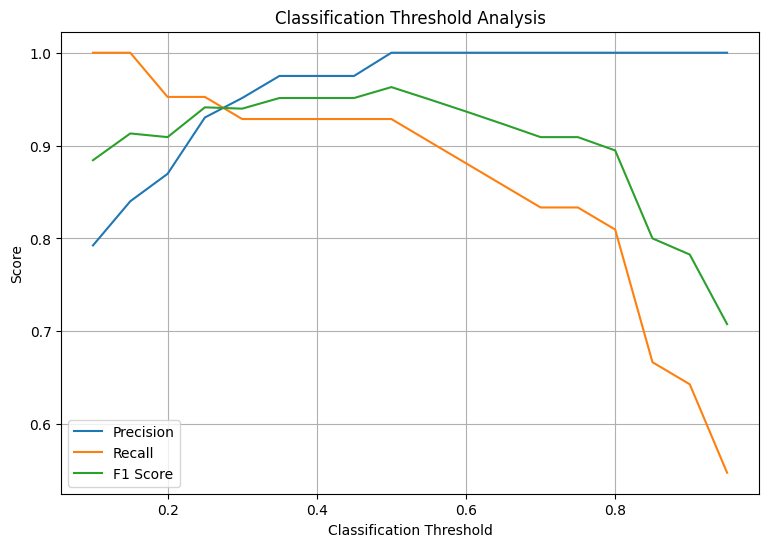

In [ ]:
# Classification threshold analysis
# Most classification models use a default threshold of 0.5.

# However, changing the threshold can influence how many malignant cases are detected.

# For example:
# - Lower threshold: Usually increases recall but may also increase false positives.
# - Higher threshold: Usually increases precision but may miss more malignant cases.

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

best_model = models["Random Forest"]

y_prob = best_model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(results)

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Classification Threshold Analysis")
plt.legend()
plt.grid()

plt.show()

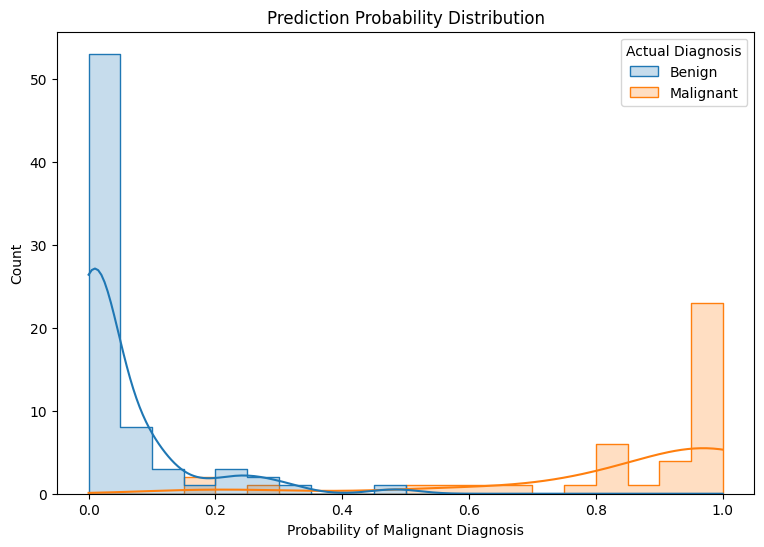

In [ ]:
# Prediction probability distribution
# Visualize the probability scores assigned to benign and malignant samples.

# This helps understand how confidently the model separates the two classes.

probabilities = best_model.predict_proba(X_test)[:, 1]

prob_df = pd.DataFrame({
    "Probability": probabilities,
    "Actual Diagnosis": y_test.map({
        0: "Benign",
        1: "Malignant"
    }).values
})

plt.figure(figsize=(9, 6))

sns.histplot(
    data=prob_df,
    x="Probability",
    hue="Actual Diagnosis",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Prediction Probability Distribution")
plt.xlabel("Probability of Malignant Diagnosis")

plt.show()

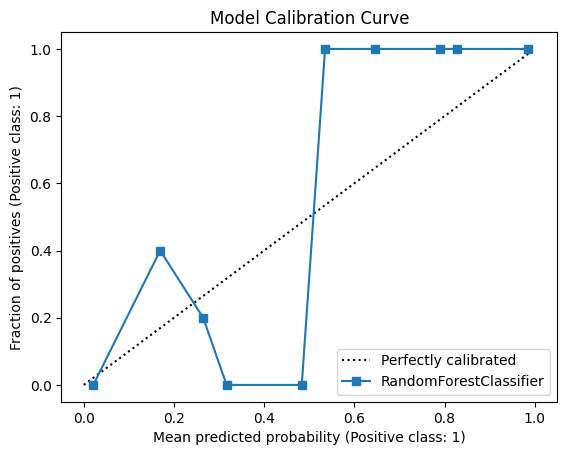

In [ ]:
# Calibration curve
# A calibration curve evaluates whether predicted probabilities reflect observed outcome frequencies.

# For example, among samples assigned a 70% probability of malignancy, approximately 70% should actually be malignant for the model to be well calibrated.
    
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    n_bins=10,
    strategy="uniform"
)

plt.title("Model Calibration Curve")
plt.show()

In [ ]:
# SHAP analysis (Model explainability)
# SHAP helps explain how individual features contribute to model predictions.

# It can provide:
# - Global feature importance.
# - Positive and negative feature contributions.
# - Individual prediction explanations.
# - Feature impact across different samples.

import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

print("SHAP shape:", shap_values.values.shape)
print("Feature shape:", X_test.shape)

SHAP shape: (114, 30, 2)
Feature shape: (114, 30)


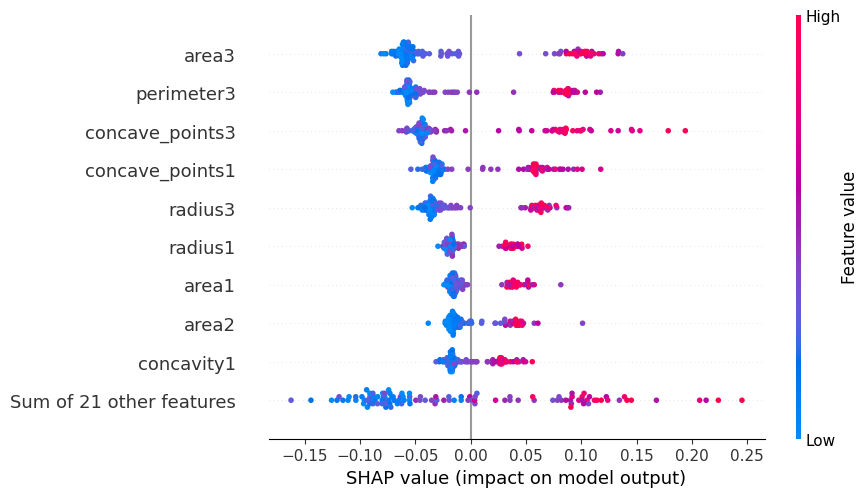

In [ ]:
# Select the malignant class
# Since your primary objective is identifying malignant cases, select class 1.
    
# Select malignant class (class 1)
shap_values_malignant = shap_values[:, :, 1]

# Generate SHAP beeswarm plot
shap.plots.beeswarm(shap_values_malignant)

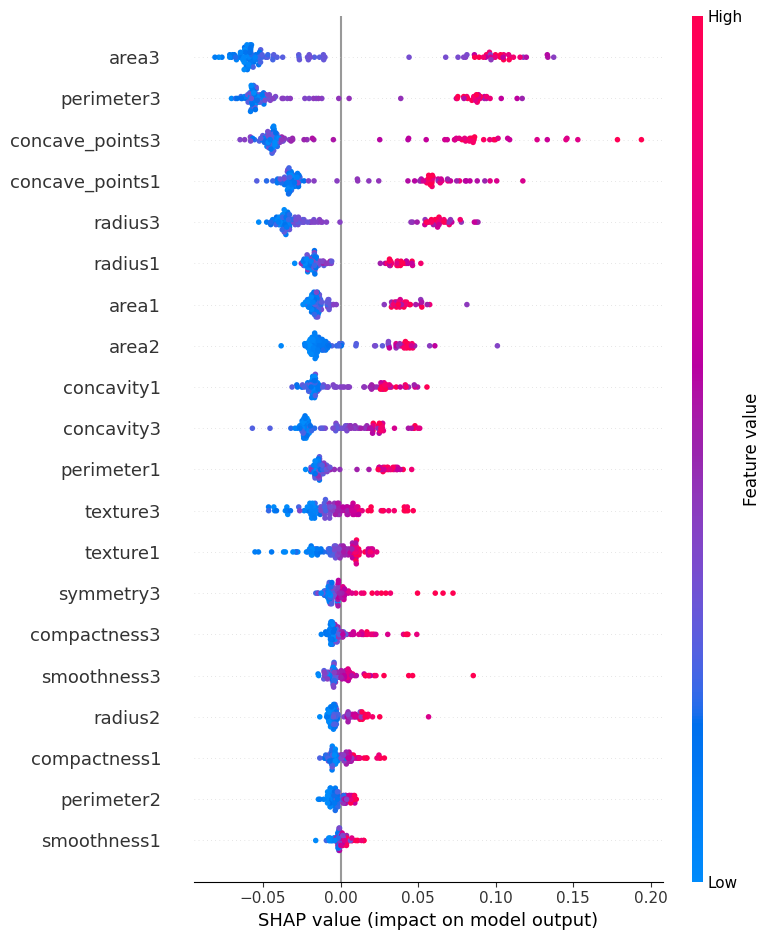

In [ ]:
# Generate additional SHAP visualizations
# Once you have selected the malignant class, you can generate these plots.

# A. SHAP Summary Plot
shap.summary_plot(
    shap_values_malignant.values,
    X_test
)

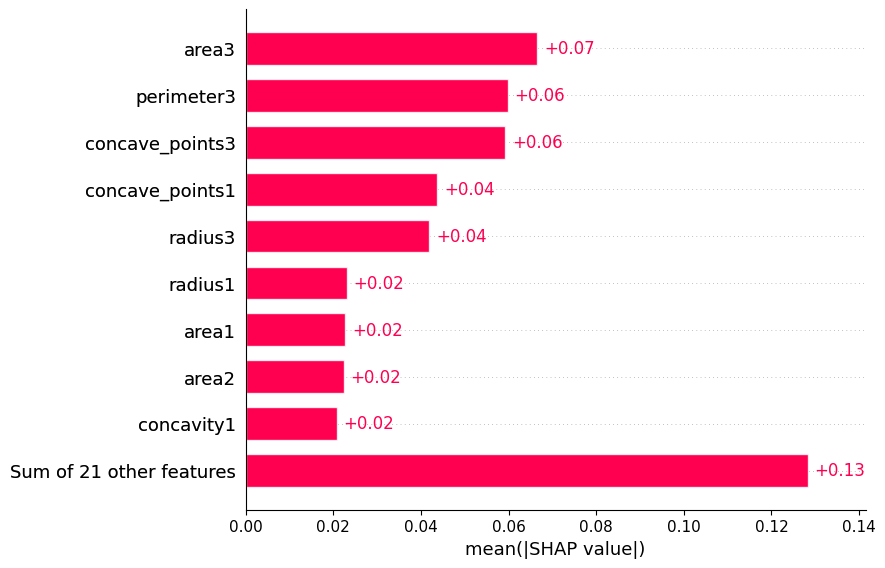

In [ ]:
# B. SHAP Feature Importance

shap.plots.bar(shap_values_malignant)

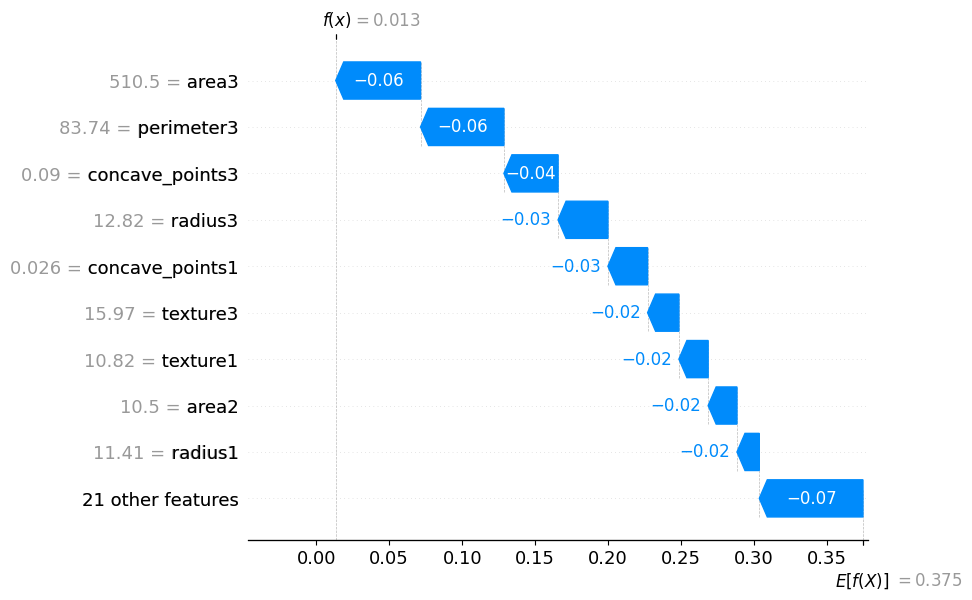

In [ ]:
# C. SHAP Waterfall Plot
# Explain an individual prediction:

shap.plots.waterfall(
    shap_values_malignant[0]
)